# 02 — Select structures, contacts, RMSD

`select_structures` fetches every mapped PDB. Chains are then kept only if sequence identity to the query is ≥ `min_identity` (default 0.6, over the **full query length**). Ligand and homodimer contacts are computed on that filtered set **before** any RMSD filter.

CA-RMSD clustering is only used to show that the SPURS representative (`config.json` → `pdb_id`) sits in a tight cluster. It does not drop structures from the contact / routing tables.

In [1]:
%matplotlib inline
from IPython.display import display
import pandas as pd

from dualde import load_example
from dualde.contacts import functional_residues, residue_contacts_from_structures
from dualde.mapping import (
    filter_hits_by_identity,
    load_structural_mapping_json,
    read_fasta,
    select_structures,
    unique_pdb_ids,
)
from dualde.rmsd import (
    plot_rmsd_cluster_counts,
    plot_rmsd_heatmap,
    rmsd_heatmap_after_alignment,
    summarize_rmsd_clusters_at_cutoff,
)

EXAMPLE, cfg = load_example()
OUT = EXAMPLE / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
PDB_DIR = EXAMPLE / "pdb"
LIGAND_NAMES = list(cfg["ligand_names"])

entries = load_structural_mapping_json(EXAMPLE / "mapping" / "pdb_hits.json")
print("chain hits:", len(entries), "unique PDBs:", unique_pdb_ids(entries))

chain hits: 30 unique PDBs: ['5bon', '5lpg', '6t5j', '7aom', '7aop', '7b63', '7b64', '7b65', '7b66', '7b7v', '7nr6', '7r0d']


## Fetch / reuse all hit PDBs

In [2]:
entries, pdb_paths = select_structures(entries, output_dir=str(PDB_DIR), fetch_missing=True)
for pid, path in sorted(pdb_paths.items()):
    print(pid, path)

5bon /lustre/scratch125/gengen/projects_v2/sgb_enzyme_design/evedesign_prelim/dualde/examples/NUDT15_HUMAN/pdb/5bon.pdb
5lpg /lustre/scratch125/gengen/projects_v2/sgb_enzyme_design/evedesign_prelim/dualde/examples/NUDT15_HUMAN/pdb/5lpg.pdb
6t5j /lustre/scratch125/gengen/projects_v2/sgb_enzyme_design/evedesign_prelim/dualde/examples/NUDT15_HUMAN/pdb/6t5j.pdb
7aom /lustre/scratch125/gengen/projects_v2/sgb_enzyme_design/evedesign_prelim/dualde/examples/NUDT15_HUMAN/pdb/7aom.pdb
7aop /lustre/scratch125/gengen/projects_v2/sgb_enzyme_design/evedesign_prelim/dualde/examples/NUDT15_HUMAN/pdb/7aop.pdb
7b63 /lustre/scratch125/gengen/projects_v2/sgb_enzyme_design/evedesign_prelim/dualde/examples/NUDT15_HUMAN/pdb/7b63.pdb
7b64 /lustre/scratch125/gengen/projects_v2/sgb_enzyme_design/evedesign_prelim/dualde/examples/NUDT15_HUMAN/pdb/7b64.pdb
7b65 /lustre/scratch125/gengen/projects_v2/sgb_enzyme_design/evedesign_prelim/dualde/examples/NUDT15_HUMAN/pdb/7b65.pdb
7b66 /lustre/scratch125/gengen/projects_

## Sequence identity ≥ 60%

Identity is identical mapped residues divided by the full query length. Unmapped query positions count as mismatches. Protein contact partners use the same cutoff.

In [3]:
_, query_seq = read_fasta(EXAMPLE / f"{cfg['protein']}.fasta")
MIN_ID = float(cfg.get("min_identity", 0.6))
n_before = len(entries)
entries, ident = filter_hits_by_identity(
    entries, pdb_paths, query_seq, min_identity=MIN_ID
)
ident.to_csv(OUT / "identity.csv", index=False)
print(f"query length {len(query_seq)}; min_identity {MIN_ID}")
print(f"chain hits: {n_before} → {len(entries)}")
print("kept PDBs:", unique_pdb_ids(entries))
display(ident.sort_values(["identity_percent", "pdb_id", "pdb_chain"], ascending=[False, True, True]))
dropped = ident.loc[ident["identity_percent"] < MIN_ID]
print("dropped:", len(dropped))
if not dropped.empty:
    display(dropped)

query length 164; min_identity 0.6
chain hits: 30 → 30
kept PDBs: ['5bon', '5lpg', '6t5j', '7aom', '7aop', '7b63', '7b64', '7b65', '7b66', '7b7v', '7nr6', '7r0d']


,pdb_id,pdb_chain,identity_percent,n_mapped
20,7b66,A,0.975610,161
0,5bon,A,0.951220,156
8,5lpg,A,0.951220,156
9,5lpg,B,0.951220,156
14,7aop,A,0.951220,156
15,7b63,A,0.951220,156
16,7b63,B,0.951220,156
2,5bon,C,0.945122,155
5,5bon,F,0.945122,155
7,5bon,H,0.945122,155


dropped: 0


## Contacts on ≥60% identity hits (before RMSD)

Protein partners whose chain identity to the query is ≥ `min_identity` are `homodimer`. Named HETATM residues in `config.json` are `ligand`.

In [4]:
contacts = residue_contacts_from_structures(
    entries,
    pdb_paths,
    ligand_names=LIGAND_NAMES,
    distance_cutoff=cfg.get("contact_distance_cutoff", 8.0),
    include_protein=True,
    query_seq=query_seq,
    min_identity=MIN_ID,
)
contacts.to_csv(OUT / "contacts.csv", index=False)
print("contacts", contacts.shape)
print("PDBs:", sorted(contacts["pdb_id"].unique()))
print(contacts["contact_type"].value_counts())
print(
    "ligand names:",
    sorted(contacts.loc[contacts["contact_type"] == "ligand", "residue_name"].unique()),
)
display(contacts.head())

contacts (13361, 9)
PDBs: ['5bon', '5lpg', '6t5j', '7aom', '7aop', '7b63', '7b64', '7b65', '7b66', '7b7v', '7nr6', '7r0d']
contact_type
homodimer    12378
ligand         983
Name: count, dtype: int64
ligand names: ['4DG', '71V', 'MKB', 'RDZ', 'RQ2', 'RTW', 'SYW', 'UO8']


,target_pos,pdb_position,wt,pdb_id,chain,residue_name,partner_chain,contact_type,minimum_distance
0,9,9,G,5bon,A,LEU,B,homodimer,7.323841
1,9,9,G,5bon,A,GLU,B,homodimer,4.842657
2,9,9,G,5bon,A,PHE,B,homodimer,5.935637
3,10,10,R,5bon,A,HIS,B,homodimer,7.917031
4,10,10,R,5bon,A,LEU,B,homodimer,5.203372


In [5]:
func = functional_residues(contacts, distance_cutoff=cfg["functional_dist_cutoff"])
func.to_csv(OUT / "functional_residues.csv", index=False)
print("functional residues (<", cfg["functional_dist_cutoff"], "Å):", len(func))
print(func["contact_type"].value_counts())
print("ligand sites:")
display(func.loc[func["contact_type"] == "ligand"])
print("homodimer sites (first 12):")
display(func.loc[func["contact_type"] == "homodimer"].head(12))

functional residues (< 3.5 Å): 76
contact_type
homodimer    54
ligand       22
Name: count, dtype: int64
ligand sites:


,target_pos,minimum_distance,pdb_id,residue_name,contact_type
6,15,3.241971,6t5j,MKB,ligand
7,16,3.119327,7b66,SYW,ligand
11,34,2.808717,7b7v,4DG,ligand
12,37,2.924247,7b7v,4DG,ligand
13,38,3.204409,7b65,SYW,ligand
14,44,3.203179,7nr6,UO8,ligand
15,45,2.672945,7aom,RQ2,ligand
16,46,3.419643,7aop,RTW,ligand
17,47,2.858231,7aop,RTW,ligand
18,48,2.930096,7b66,SYW,ligand


homodimer sites (first 12):


,target_pos,minimum_distance,pdb_id,residue_name,contact_type
0,8,2.789162,7b66,PRO,homodimer
1,9,3.017963,7b66,PHE,homodimer
2,10,3.000047,5bon,HIS,homodimer
3,11,2.791201,7b66,ARG,homodimer
4,12,2.789162,7b66,ARG,homodimer
5,14,3.038318,7b65,VAL,homodimer
8,23,3.222075,7b66,ARG,homodimer
9,24,2.645590,7b66,GLU,homodimer
10,27,3.130275,5bon,GLU,homodimer
20,50,3.026612,5bon,PRO,homodimer


## RMSD (SPURS representative only)

Cluster unique PDBs by CA-RMSD. Notebook 04 still runs SPURS on the representative in `config.json`.

In [6]:
pdb_ids = unique_pdb_ids(entries)
first_chain = {}
for entry in entries:
    pid = str(entry["pdb_id"]).lower()
    ch = str(entry["pdb_chain"])
    if pid not in first_chain and len(ch) == 1:
        first_chain[pid] = ch

pdb_files, labels, chain_specs = [], [], {}
for pdb_id in pdb_ids:
    path = pdb_paths.get(pdb_id)
    if not path or not str(path).lower().endswith((".pdb", ".ent")):
        continue
    pdb_files.append(path)
    labels.append(pdb_id)
    if pdb_id in first_chain:
        chain_specs[path] = first_chain[pdb_id]

rmsd_df, cleaned = rmsd_heatmap_after_alignment(
    pdb_files=pdb_files,
    chain_specs=chain_specs or None,
    output_dir=str(PDB_DIR),
    labels=labels,
    show=False,
)
rmsd_df.to_csv(OUT / "rmsd_matrix.csv")
print(rmsd_df.round(3))

       5bon   5lpg   6t5j   7aom   7aop   7b63   7b64   7b65   7b66   7b7v  \
5bon  0.000  0.574  0.805  0.380  0.746  0.845  0.833  0.569  0.864  0.690   
5lpg  0.574  0.000  0.443  0.419  0.484  0.668  0.790  0.557  0.783  0.435   
6t5j  0.805  0.443  0.000  0.701  0.604  0.430  0.608  0.650  0.641  0.675   
7aom  0.380  0.419  0.701  0.000  0.599  0.649  0.571  0.572  0.524  0.486   
7aop  0.746  0.484  0.604  0.599  0.000  0.794  0.899  0.629  0.855  0.570   
7b63  0.845  0.668  0.430  0.649  0.794  0.000  0.545  0.439  0.636  0.639   
7b64  0.833  0.790  0.608  0.571  0.899  0.545  0.000  0.167  0.310  0.670   
7b65  0.569  0.557  0.650  0.572  0.629  0.439  0.167  0.000  0.278  0.705   
7b66  0.864  0.783  0.641  0.524  0.855  0.636  0.310  0.278  0.000  0.583   
7b7v  0.690  0.435  0.675  0.486  0.570  0.639  0.670  0.705  0.583  0.000   
7nr6  0.725  0.350  0.541  0.510  0.429  0.563  0.683  0.717  0.608  0.314   

       7nr6  
5bon  0.725  
5lpg  0.350  
6t5j  0.541  
7aom  0

SPURS representative: 5lpg


,label,cluster
0,5bon,1
1,5lpg,1
2,6t5j,1
3,7aom,1
4,7aop,1
5,7b63,1
6,7b64,1
7,7b65,1
8,7b66,1
9,7b7v,1


RMSD cutoff = 2.00 A -> 1 cluster(s) across 11 structure(s)
cluster
1    [5bon, 5lpg, 6t5j, 7aom, 7aop, 7b63, 7b64, 7b6...


(<Axes: title={'center': 'RMSD cluster count vs cutoff'}, xlabel='RMSD cutoff (A)', ylabel='Number of clusters'>,
     cutoff  n_clusters
 0     0.25          10
 1     0.50           4
 2     0.75           1
 3     1.00           1
 4     1.25           1
 5     1.50           1
 6     1.75           1
 7     2.00           1
 8     2.25           1
 9     2.50           1
 10    2.75           1
 11    3.00           1
 12    3.25           1
 13    3.50           1
 14    3.75           1
 15    4.00           1
 16    4.25           1
 17    4.50           1
 18    4.75           1
 19    5.00           1)

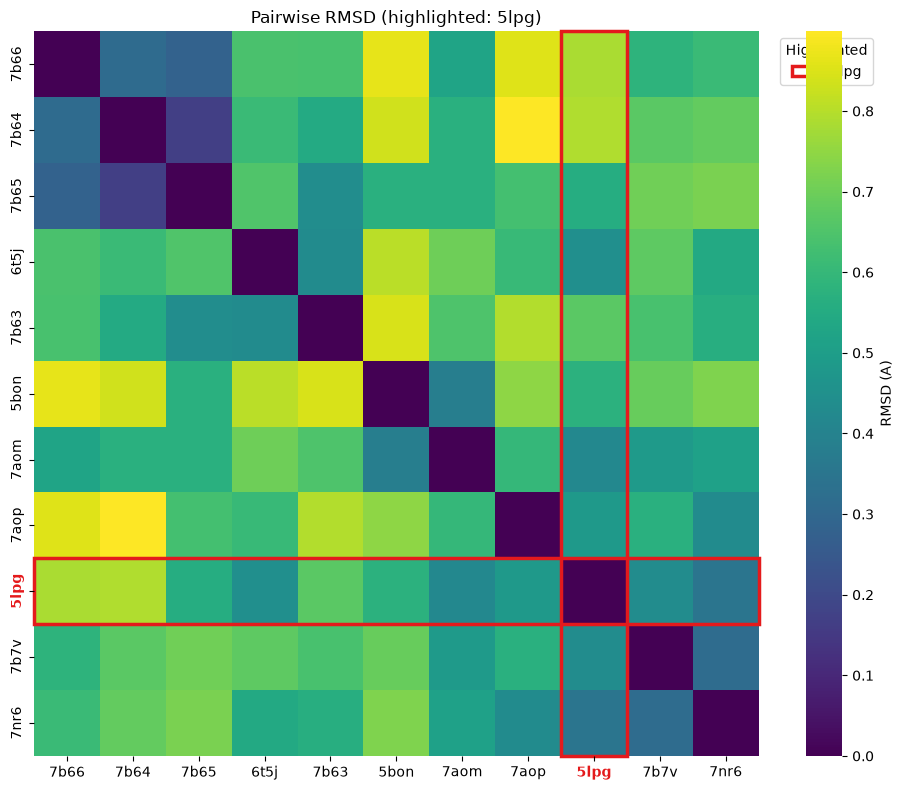

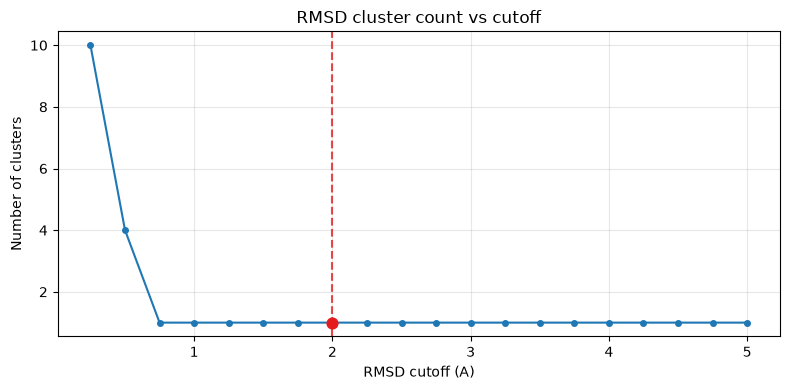

In [7]:
CUTOFF = float(cfg["rmsd_cutoff"])
summary = summarize_rmsd_clusters_at_cutoff(rmsd_df, cutoff=CUTOFF)
summary.to_csv(OUT / "rmsd_clusters.csv", index=False)
print("SPURS representative:", cfg["pdb_id"])
display(summary)
plot_rmsd_heatmap(rmsd_df, highlight_pdb=cfg["pdb_id"])
plot_rmsd_cluster_counts(rmsd_df, cutoff=CUTOFF)